# 03 — Corrected evaluation

Threshold on validation, 30-day embargo, block bootstrap, extrapolation baseline. Same pipeline as `scripts/run_main.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))

from run_main import prepare_asset, ASSETS, EMBARGO, HORIZON
from src.features import COLUMN_ORDER
from src.models import RFCModel, XGBModel
from src.baselines import extrapolation_rule, stratified_expected_f1
from src.evaluation import (fit_with_validation_threshold, calibrate_threshold,
                            block_bootstrap_f1, iid_bootstrap_f1, walk_forward)

## Data

In [2]:
data = {t: prepare_asset(t) for t in ASSETS}
pd.DataFrame([{
    'Asset': t, 'Test_start': te['Date'].iloc[0].date(), 'N_train': len(tr), 'N_test': len(te),
    'Pos_train': round(tr['Transition'].mean(), 3), 'Pos_test': round(te['Transition'].mean(), 3),
    'Crossings_test': int(te['Crossing'].sum()),
} for t, (tr, te, _, _) in data.items()])

,Asset,Test_start,N_train,N_test,Pos_train,Pos_test,Crossings_test
0,SPY,2018-12-13,4563,1521,0.116,0.099,5
1,DIA,2018-12-13,4563,1521,0.151,0.103,6
2,QQQ,2018-12-13,4563,1521,0.144,0.087,5
3,GLD,2020-03-04,3643,1215,0.131,0.225,10
4,TLT,2019-08-06,4080,1360,0.203,0.194,9


## Training on SPY, threshold on validation

In [3]:
train = data['SPY'][0]
X_tr, y_tr = train[COLUMN_ORDER], train['Transition']

models = {}
for name, cls in [('XGB', XGBModel), ('RFC', RFCModel)]:
    model, th, val_f1 = fit_with_validation_threshold(cls, {}, X_tr, y_tr, embargo=EMBARGO)
    models[name] = (model, th)
    print(f"{name}: threshold={th:.2f}  validation F1={val_f1:.3f}")

XGB: threshold=0.20  validation F1=0.792


RFC: threshold=0.45  validation F1=0.760


## Test results

In [4]:
rows = []
for t, (_, te, _, _) in data.items():
    X_te, y_te = te[COLUMN_ORDER], te['Transition'].values
    preds = {n: (m.predict_proba(X_te) >= th).astype(int) for n, (m, th) in models.items()}
    preds['Extrapolation'] = extrapolation_rule(X_te, HORIZON)
    for n, p in preds.items():
        lo, hi = block_bootstrap_f1(y_te, p, block=HORIZON)
        rows.append({'Asset': t, 'Model': n, 'P': precision_score(y_te, p), 'R': recall_score(y_te, p),
                     'F1': f1_score(y_te, p), 'CI_low': lo, 'CI_high': hi, 'N_pred': int(p.sum())})
    rows.append({'Asset': t, 'Model': 'Stratified', 'F1': stratified_expected_f1(y_tr.mean(), y_te.mean())})

res = pd.DataFrame(rows).round(3)
res

,Asset,Model,P,R,F1,CI_low,CI_high,N_pred
0,SPY,XGB,0.457,0.887,0.603,0.384,0.771,291.0
1,SPY,RFC,0.535,0.820,0.647,0.426,0.794,230.0
2,SPY,Extrapolation,0.748,0.693,0.720,0.489,0.865,139.0
3,SPY,Stratified,NaN,NaN,0.106,NaN,NaN,NaN
4,DIA,XGB,0.415,0.834,0.554,0.324,0.692,316.0
5,DIA,RFC,0.533,0.828,0.648,0.409,0.782,244.0
6,DIA,Extrapolation,0.609,0.586,0.597,0.382,0.769,151.0
7,DIA,Stratified,NaN,NaN,0.109,NaN,NaN,NaN
8,QQQ,XGB,0.468,0.947,0.627,0.393,0.788,267.0
9,QQQ,RFC,0.457,0.886,0.603,0.341,0.766,256.0


In [5]:
res[res['Asset'].isin(['SPY', 'DIA', 'QQQ'])].groupby('Model')['F1'].mean().round(3)

Model
Extrapolation    0.720
RFC              0.633
Stratified       0.105
XGB              0.595
Name: F1, dtype: float64

## Same models, threshold picked on the SPY test set (protocol of notebook 02)

In [6]:
test_spy = data['SPY'][1]
naive = []
for name, cls in [('XGB', XGBModel), ('RFC', RFCModel)]:
    m = cls().fit(X_tr, y_tr)
    th, _ = calibrate_threshold(test_spy['Transition'], m.predict_proba(test_spy[COLUMN_ORDER]))
    for t, (_, te, _, _) in data.items():
        p = (m.predict_proba(te[COLUMN_ORDER]) >= th).astype(int)
        lo, hi = iid_bootstrap_f1(te['Transition'], p)
        naive.append({'Asset': t, 'Model': name, 'Threshold': th, 'F1': f1_score(te['Transition'], p),
                      'CI_iid_low': lo, 'CI_iid_high': hi})
naive = pd.DataFrame(naive).round(3)
naive

,Asset,Model,Threshold,F1,CI_iid_low,CI_iid_high
0,SPY,XGB,0.90,0.762,0.698,0.815
1,DIA,XGB,0.90,0.683,0.618,0.740
2,QQQ,XGB,0.90,0.769,0.705,0.824
3,GLD,XGB,0.90,0.661,0.600,0.713
4,TLT,XGB,0.90,0.618,0.558,0.676
5,SPY,RFC,0.65,0.763,0.709,0.810
6,DIA,RFC,0.65,0.653,0.592,0.706
7,QQQ,RFC,0.65,0.745,0.685,0.798
8,GLD,RFC,0.65,0.737,0.693,0.776
9,TLT,RFC,0.65,0.643,0.596,0.683


In [7]:
naive[naive['Asset'].isin(['SPY', 'DIA', 'QQQ'])].groupby('Model')['F1'].mean().round(3)

Model
RFC    0.720
XGB    0.738
Name: F1, dtype: float64

## Walk-forward on SPY

In [8]:
full = pd.concat([data['SPY'][0], data['SPY'][1]], ignore_index=True)
for name, cls in [('XGB', XGBModel), ('RFC', RFCModel)]:
    folds, pooled = walk_forward(full[COLUMN_ORDER], full['Transition'], cls, {}, embargo=EMBARGO)
    print(f"{name}: pooled F1={pooled:.3f}")
    display(folds)

XGB: pooled F1=0.651


,Fold,Train_size,N_positive,Threshold,F1
0,1,3042,0,NaN,NaN
1,2,3650,115,0.10,0.792
2,3,4258,68,0.15,0.562
3,4,4866,82,0.80,0.790
4,5,5474,30,0.40,0.387


RFC: pooled F1=0.638


,Fold,Train_size,N_positive,Threshold,F1
0,1,3042,0,NaN,NaN
1,2,3650,115,0.10,0.691
2,3,4258,68,0.40,0.642
3,4,4866,82,0.75,0.725
4,5,5474,30,0.45,0.420


## Sensitivity to 1e-6 price perturbations

Output of `scripts/perturbation.py`.

In [9]:
pert = pd.read_csv(PROJECT_ROOT / 'results' / 'perturbation.csv')
pert = pert[pert['Rep'] > 0]
pert[pert['Asset'].isin(['SPY', 'DIA', 'QQQ'])].groupby(['Rep', 'Model'])['F1'].mean().unstack().describe().round(3)

Model,Extrapolation,RFC,XGB
count,20.00,20.000,20.000
mean,0.72,0.634,0.609
std,0.00,0.001,0.012
min,0.72,0.633,0.596
25%,0.72,0.633,0.600
50%,0.72,0.634,0.608
75%,0.72,0.635,0.613
max,0.72,0.635,0.643


## Figures

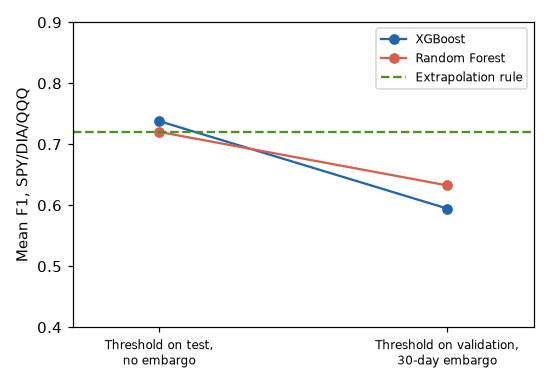

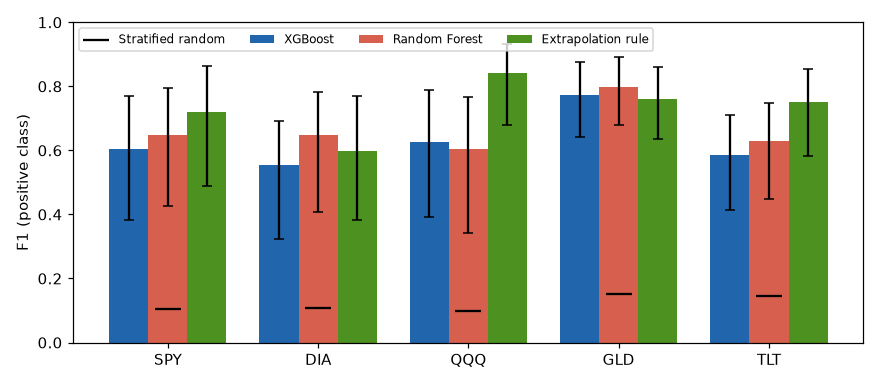

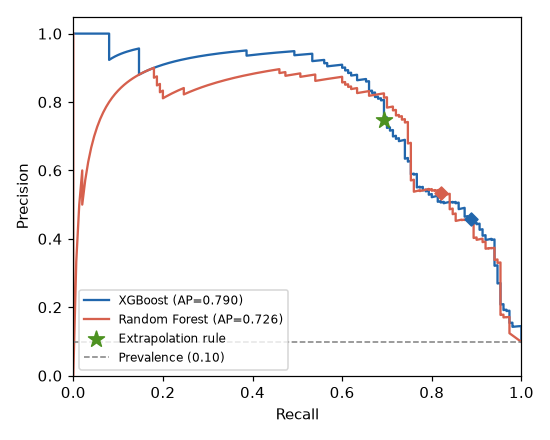

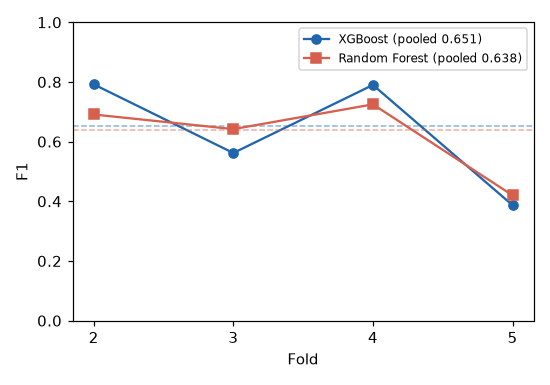

In [10]:
from IPython.display import Image
for f in ['protocol_effect', 'f1_block_ci', 'pr_curve_spy', 'walk_forward']:
    display(Image(str(PROJECT_ROOT / 'figures' / f'{f}.png')))